# VinDr-CXR: U-Net Baseline

This notebook trains a small U-Net to reproduce **bounding-box-derived pseudo-masks** for the validated VinDr-CXR subset.

**Important limitation:** these are filled rectangles from radiologist bounding boxes, not pixel-level lesion segmentation masks. The model is learning to approximate the boxes, not true lesion boundaries. Treat the results as a pipeline prototype only.

## 1. Install dependencies

Run this cell once in the notebook's active project environment. Restart the kernel if packages were installed or upgraded.

In [16]:
%pip install torch torchvision pydicom pylibjpeg pylibjpeg-openjpeg pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and project paths

The notebook expects the project structure to contain `data/processed/validated_manifest.csv` and `data/annotations/annotations_train.csv`.

In [17]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

SEED = 42
SIZE = 256
BATCH_SIZE = 4
EPOCHS = 10
LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Find the project root, whether the notebook runs from the root or notebooks/
ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError(
            "Could not find the project root. Open this notebook from "
            "the chest-xray-ai-annotation project."
        )
    ROOT = ROOT.parent

MANIFEST_PATH = ROOT / "data" / "processed" / "validated_manifest.csv"
ANNOTATIONS_PATH = ROOT / "data" / "annotations" / "annotations_train.csv"

manifest = pd.read_csv(MANIFEST_PATH, dtype={"image_id": str})
annotations = pd.read_csv(ANNOTATIONS_PATH, dtype={"image_id": str})

# Keep only images flagged as having bounding boxes.
# The manifest may read this column as bool or text depending on how it was saved.
has_bbox = manifest["has_bbox"].astype(str).str.lower().isin(["true", "1", "yes"])
sample = manifest.loc[has_bbox].drop_duplicates("image_id").reset_index(drop=True)

print("Project root:", ROOT)
print("Validated images in manifest:", manifest["image_id"].nunique())
print("Unique images with bounding boxes:", len(sample))
print("Device will be selected in the training section.")

Project root: c:\Users\johnm\chest-xray-ai-annotation
Validated images in manifest: 295
Unique images with bounding boxes: 100
Device will be selected in the training section.


## 3. Convert DICOMs and bounding boxes into model inputs

Each X-ray is resized to 256 × 256. Each bounding box is filled to create a binary pseudo-mask. Multiple radiologists' boxes are combined into one union mask for this baseline.

Images that fail to decode are skipped and reported.

In [18]:

# ============================================================
# PREPROCESSING: DICOM IMAGES + R10 BOUNDING-BOX PSEUDO-MASKS
# ============================================================

def load_image_and_mask(row, size=SIZE):
    """Load one DICOM image and create a mask from R10's boxes."""

    # 1. Read the DICOM and decode its pixel array.
    dicom_path = ROOT / row["dicom_path"]
    ds = pydicom.dcmread(str(dicom_path))
    image = ds.pixel_array.astype(np.float32)

    if image.ndim != 2:
        raise ValueError(f"Expected a 2D X-ray, got {image.shape}")

    original_h, original_w = image.shape

    # 2. Normalize intensities robustly to the range [0, 1].
    lo, hi = np.percentile(image, [1, 99])

    if hi > lo:
        image = np.clip(image, lo, hi)
        image = (image - lo) / (hi - lo)
    else:
        image = np.zeros_like(image, dtype=np.float32)

    # 3. Invert MONOCHROME1 images for consistent display.
    if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
        image = 1.0 - image

    # 4. Resize the X-ray to the model's input dimensions.
    image_tensor = torch.from_numpy(image)[None, None]
    image = F.interpolate(
        image_tensor,
        size=(size, size),
        mode="bilinear",
        align_corners=False,
    )[0, 0].numpy()

    # 5. Select only R10's valid bounding boxes for this image.
    image_boxes = annotations[
        (annotations["image_id"].astype(str) == str(row["image_id"]))
        & (annotations["rad_id"].astype(str) == "R10")
    ].dropna(subset=["x_min", "y_min", "x_max", "y_max"])

    # A missing R10 box is not automatically a negative finding.
    if image_boxes.empty:
        raise ValueError("No valid bounding boxes from radiologist R10")

    # 6. Convert the boxes into a binary pseudo-mask.
    #    These filled rectangles are NOT true lesion contours.
    mask = np.zeros((size, size), dtype=np.float32)

    for _, box in image_boxes.iterrows():
        x_min = float(box["x_min"])
        y_min = float(box["y_min"])
        x_max = float(box["x_max"])
        y_max = float(box["y_max"])

        # Skip invalid or zero-area boxes.
        if x_max <= x_min or y_max <= y_min:
            continue

        # Convert original-image coordinates to resized coordinates.
        x1 = int(np.floor(x_min / original_w * size))
        x2 = int(np.ceil(x_max / original_w * size))
        y1 = int(np.floor(y_min / original_h * size))
        y2 = int(np.ceil(y_max / original_h * size))

        # Clip coordinates to image boundaries.
        x1, x2 = np.clip([x1, x2], 0, size)
        y1, y2 = np.clip([y1, y2], 0, size)

        if x2 > x1 and y2 > y1:
            mask[y1:y2, x1:x2] = 1.0

    if mask.sum() == 0:
        raise ValueError("R10 annotations produced an empty mask")

    return image.astype(np.float32), mask


# ============================================================
# BUILD THE DATASET
# ============================================================

images, masks, loaded_ids, failed_images = [], [], [], []

for _, row in sample.iterrows():
    try:
        image, mask = load_image_and_mask(row)

        images.append(image)
        masks.append(mask)
        loaded_ids.append(str(row["image_id"]))

    except Exception as exc:
        failed_images.append((str(row["image_id"]), str(exc)))

if not images:
    raise RuntimeError(
        "No usable images found. Check R10 annotations and manifest paths."
    )

images = np.stack(images)
masks = np.stack(masks)

print("Radiologist used: R10")
print("Images loaded:", len(images))
print("Image array shape:", images.shape)
print("Pseudo-mask array shape:", masks.shape)
print("Mean positive-mask fraction:", round(float(masks.mean()), 4))
print("Images skipped:", len(failed_images))

if failed_images:
    print("\nSkipped image IDs and reasons:")
    for image_id, reason in failed_images:
        print(f"  {image_id}: {reason}")

# Flag unusually large masks for inspection, not automatic deletion.
coverage = masks.mean(axis=(1, 2))
large_mask_count = int((coverage > 0.50).sum())

print("Masks covering more than 50% of an image:", large_mask_count)


Radiologist used: R10
Images loaded: 89
Image array shape: (89, 256, 256)
Pseudo-mask array shape: (89, 256, 256)
Mean positive-mask fraction: 0.0666
Images skipped: 11

Skipped image IDs and reasons:
  1409d26e536b423b2a8d4fb117ea1db4: No valid bounding boxes from radiologist R10
  1a414a1cb6b545c2ee4de4abede481c7: No valid bounding boxes from radiologist R10
  1f897eadcbbca4e2104e7a2d7fd3e0f9: No valid bounding boxes from radiologist R10
  4c4cf43e7c8529c430c1d1295fee1784: No valid bounding boxes from radiologist R10
  4e05e0eb20d51d18764289ce2c240942: No valid bounding boxes from radiologist R10
  4f58c1bba4416c27de765e6120ea84e1: No valid bounding boxes from radiologist R10
  886159a41e7589ba0d0713980591e27d: No valid bounding boxes from radiologist R10
  a0e0a66c5bc7a660f082ba3363c4a96a: No valid bounding boxes from radiologist R10
  d542a2d31e52e44775ed46b028cc0041: No valid bounding boxes from radiologist R10
  dd56e45f5a420deeea392f45fedee77c: No valid bounding boxes from radio

## 4. Inspect one input and its pseudo-mask

Check that the red regions align with the boxes. The mask intentionally contains full rectangles, including normal anatomy inside each box.

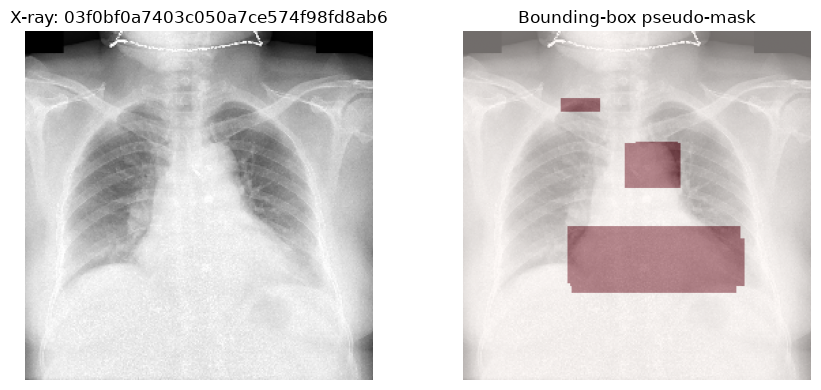

In [4]:
idx = 0

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(images[idx], cmap="gray")
ax[0].set_title(f"X-ray: {loaded_ids[idx]}")
ax[0].axis("off")

ax[1].imshow(images[idx], cmap="gray")
ax[1].imshow(masks[idx], cmap="Reds", alpha=0.45, vmin=0, vmax=1)
ax[1].set_title("Bounding-box pseudo-mask")
ax[1].axis("off")

plt.tight_layout()
plt.show()

## 5. Train/validation split and data loaders

The split is performed by image, so the same image cannot appear in both sets. The validation set is held out from gradient updates.

In [19]:

# ============================================================
# TRAIN / VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
BATCH_SIZE = 4

# Split by image so an image cannot occur in both sets.
indices = np.arange(len(images))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED
)

# Add a channel dimension: (N, 1, 256, 256).
X = torch.from_numpy(images[:, None]).float()
Y = torch.from_numpy(masks[:, None]).float()

train_ds = TensorDataset(X[train_idx], Y[train_idx])
val_ds = TensorDataset(X[val_idx], Y[val_idx])

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Device:", device)
print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Training mask coverage:", round(float(Y[train_idx].mean()), 4))
print("Validation mask coverage:", round(float(Y[val_idx].mean()), 4))


Device: cpu
Training images: 71
Validation images: 18
Training mask coverage: 0.0662
Validation mask coverage: 0.0684


## 6. Define a small U-Net

The network takes one grayscale channel and returns one logit per pixel. A sigmoid is applied only when converting logits to probabilities for visualization or metrics.

In [20]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = conv_block(1, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = conv_block(64, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec3 = conv_block(128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = conv_block(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = conv_block(32, 16)

        self.output_layer = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.output_layer(d1)


model = UNet().to(device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable parameters: 481745


## 7. Loss function and optimizer

BCE handles per-pixel classification; Dice loss encourages overlap with the target mask. The combined loss is a training objective, not a clinical performance metric.

In [21]:
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, smooth=1.0):
    probabilities = torch.sigmoid(logits)
    probabilities = probabilities.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (probabilities * targets).sum(dim=1)
    denominator = probabilities.sum(dim=1) + targets.sum(dim=1)
    dice = (2 * intersection + smooth) / (denominator + smooth)
    return 1.0 - dice.mean()


def combined_loss(logits, targets):
    return bce_loss(logits, targets) + dice_loss(logits, targets)


criterion = combined_loss
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

## 8. Train U-Net

This baseline runs for 10 epochs. Both losses are averaged per image. Training loss should generally trend down, but loss alone cannot prove that predictions are useful.

Epoch 01/10 | Train loss: 1.3841 | Val loss: 1.2851
Epoch 02/10 | Train loss: 1.2256 | Val loss: 1.2011
Epoch 03/10 | Train loss: 1.1870 | Val loss: 1.1728
Epoch 04/10 | Train loss: 1.1738 | Val loss: 1.1680
Epoch 05/10 | Train loss: 1.1724 | Val loss: 1.1586
Epoch 06/10 | Train loss: 1.1700 | Val loss: 1.1553
Epoch 07/10 | Train loss: 1.1692 | Val loss: 1.1585
Epoch 08/10 | Train loss: 1.1656 | Val loss: 1.1612
Epoch 09/10 | Train loss: 1.1693 | Val loss: 1.1581
Epoch 10/10 | Train loss: 1.1738 | Val loss: 1.1638


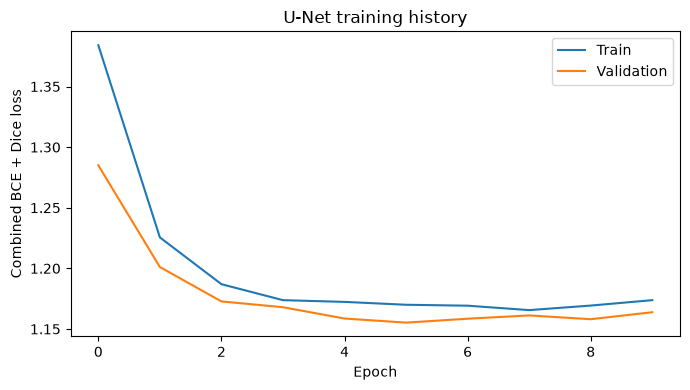

In [22]:
history = {"train_loss": [], "val_loss": []}

for epoch in range(EPOCHS):
    model.train()
    train_total = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_total += loss.item() * xb.size(0)

    model.eval()
    val_total = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)
            val_total += criterion(model(xb), yb).item() * xb.size(0)

    train_loss_value = train_total / len(train_ds)
    val_loss_value = val_total / len(val_ds)
    history["train_loss"].append(train_loss_value)
    history["val_loss"].append(val_loss_value)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss_value:.4f} | "
        f"Val loss: {val_loss_value:.4f}"
    )

# Plot the training curves.
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Combined BCE + Dice loss")
plt.title("U-Net training history")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Evaluate on the held-out validation set

Dice and IoU are calculated against the box-derived pseudo-masks at a fixed threshold of 0.5. They measure agreement with these rectangles, not true lesion segmentation accuracy.

In [23]:
THRESHOLD = 0.5
dice_scores, iou_scores = [], []
model.eval()

with torch.no_grad():
    for xb, yb in val_loader:
        logits = model(xb.to(device))
        predictions = (torch.sigmoid(logits) >= THRESHOLD).float()
        targets = yb.to(device)

        predictions = predictions.flatten(start_dim=1)
        targets = targets.flatten(start_dim=1)

        intersection = (predictions * targets).sum(dim=1)
        pred_area = predictions.sum(dim=1)
        target_area = targets.sum(dim=1)
        union = pred_area + target_area - intersection

        dice = (2 * intersection + 1e-7) / (pred_area + target_area + 1e-7)
        iou = (intersection + 1e-7) / (union + 1e-7)

        dice_scores.extend(dice.cpu().tolist())
        iou_scores.extend(iou.cpu().tolist())

print(f"Validation Dice (pseudo-mask agreement): {np.mean(dice_scores):.4f}")
print(f"Validation IoU  (pseudo-mask agreement): {np.mean(iou_scores):.4f}")
print(f"Threshold: {THRESHOLD}")

Validation Dice (pseudo-mask agreement): 0.0000
Validation IoU  (pseudo-mask agreement): 0.0000
Threshold: 0.5


## 10. Visualize a validation prediction

Compare the target rectangles with the model output. A blank or overly broad prediction indicates the model has not learned to reproduce the pseudo-masks well yet.

Probability range: 0.0020838442724198103 to 0.2908773422241211
Mean probability: 0.13854636251926422
Predicted positive fraction: 0.0
Target positive fraction: 0.1080322265625


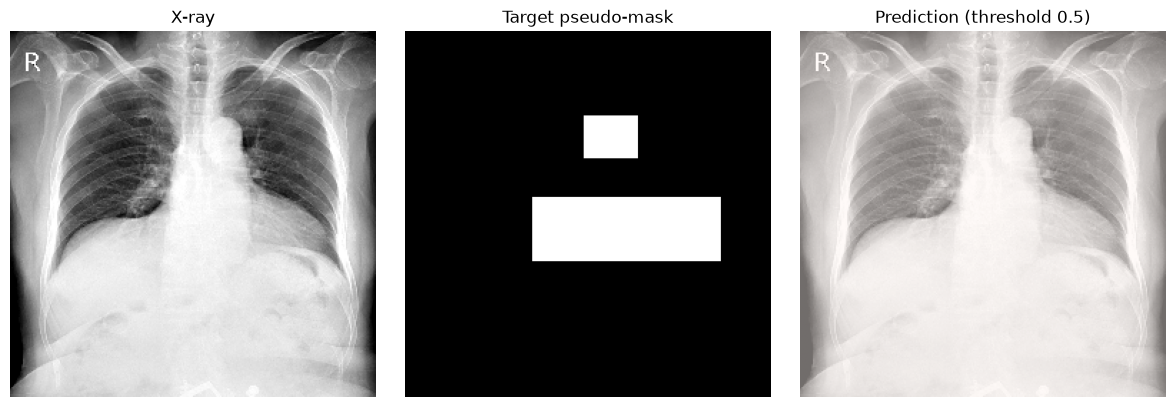

In [24]:
model.eval()
xb, yb = next(iter(val_loader))

with torch.no_grad():
    probabilities = torch.sigmoid(model(xb.to(device))).cpu()

image = xb[0, 0].numpy()
target = yb[0, 0].numpy()
probability_map = probabilities[0, 0].numpy()
predicted_mask = probability_map >= THRESHOLD

print("Probability range:", float(probability_map.min()), "to", float(probability_map.max()))
print("Mean probability:", float(probability_map.mean()))
print("Predicted positive fraction:", float(predicted_mask.mean()))
print("Target positive fraction:", float(target.mean()))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(image, cmap="gray")
ax[0].set_title("X-ray")
ax[1].imshow(target, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Target pseudo-mask")
ax[2].imshow(image, cmap="gray")
ax[2].imshow(predicted_mask, cmap="Reds", alpha=0.45)
ax[2].set_title(f"Prediction (threshold {THRESHOLD})")

for axis in ax:
    axis.axis("off")

plt.tight_layout()
plt.show()

## 11. Save the model

The checkpoint stores model weights and the input size. Keep the notebook, manifest, and annotation CSVs with the experiment so the run can be reproduced.

In [25]:
model_path = ROOT / "data" / "processed" / "unet_bbox_pseudomask_baseline.pt"
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_size": SIZE,
        "threshold": THRESHOLD,
        "seed": SEED,
        "target_type": "bounding-box-derived pseudo-mask",
    },
    model_path,
)
print("Model checkpoint saved to:", model_path)

Model checkpoint saved to: c:\Users\johnm\chest-xray-ai-annotation\data\processed\unet_bbox_pseudomask_baseline.pt


In [26]:

# Find images whose bounding-box pseudo-masks cover the largest areas.
mask_fractions = masks.mean(axis=(1, 2))
largest_indices = np.argsort(mask_fractions)[::-1][:10]

print("10 images with the largest positive-mask fractions:\n")

for i in largest_indices:
    print(f"{loaded_ids[i]}  |  mask coverage: {mask_fractions[i]:.1%}")

# Inspect the annotation rows for the largest mask.
idx = largest_indices[0]
image_id = loaded_ids[idx]

print(f"\nBounding boxes for image: {image_id}")

box_rows = annotations[
    annotations["image_id"].astype(str) == str(image_id)
].dropna(subset=["x_min", "y_min", "x_max", "y_max"])

print(
    box_rows[
        ["rad_id", "class_name", "x_min", "y_min", "x_max", "y_max"]
    ].to_string(index=False)
)


10 images with the largest positive-mask fractions:

0d30dc1e0070e7a934f39452e3ad3b83  |  mask coverage: 38.4%
8111591b7fea74653fbd7e935a74cf36  |  mask coverage: 22.5%
ef50301bda56ee37e33b99fde2be8c7f  |  mask coverage: 17.4%
4b9ee23b2f17c3621158a9bef81cf86b  |  mask coverage: 16.1%
0a0ac65c40a9ac441651e4bfbde03c4e  |  mask coverage: 15.7%
6f81359c392e30ddea9260b22d732e69  |  mask coverage: 14.4%
eb6c714df22142229464c6b83e47d7d6  |  mask coverage: 13.8%
d0ea942db524a895c4bc433e03c3cd3a  |  mask coverage: 13.7%
69972b49aac9f4aea137e51984cf8691  |  mask coverage: 13.2%
224ad5cca3b13b0a820052fe0491699a  |  mask coverage: 12.4%

Bounding boxes for image: 0d30dc1e0070e7a934f39452e3ad3b83
rad_id         class_name       x_min       y_min       x_max       y_max
   R10       Pneumothorax  374.290985 1262.869995 1548.469971 1540.589966
   R10       Other lesion  374.290985 1262.869995 1548.469971 1540.589966
   R10       Other lesion 1812.209961  452.990997 2040.229980 2231.510010
   R10     

In [27]:

# Check which bounding boxes occupy the largest area of each image.
box_data = annotations.dropna(
    subset=["x_min", "y_min", "x_max", "y_max"]
).copy()

# Get original DICOM dimensions for each loaded image.
dimensions = {}
for _, row in sample.iterrows():
    image_id = str(row["image_id"])
    if image_id not in loaded_ids:
        continue
    try:
        ds = pydicom.dcmread(str(ROOT / row["dicom_path"]),
                             stop_before_pixels=True)
        dimensions[image_id] = (ds.Columns, ds.Rows)
    except Exception:
        pass

box_data["image_id"] = box_data["image_id"].astype(str)
box_data["image_width"] = box_data["image_id"].map(
    lambda i: dimensions[i][0] if i in dimensions else np.nan
)
box_data["image_height"] = box_data["image_id"].map(
    lambda i: dimensions[i][1] if i in dimensions else np.nan
)

box_data["box_fraction"] = (
    (box_data["x_max"] - box_data["x_min"]).clip(lower=0)
    * (box_data["y_max"] - box_data["y_min"]).clip(lower=0)
    / (box_data["image_width"] * box_data["image_height"])
)

print(
    box_data.sort_values("box_fraction", ascending=False)[
        ["image_id", "rad_id", "class_name", "box_fraction"]
    ].head(15).to_string(index=False)
)


                        image_id rad_id         class_name  box_fraction
0d30dc1e0070e7a934f39452e3ad3b83     R9       Other lesion      0.938753
d653c05dad30d8c04fa23fdac2572ab6     R9       Other lesion      0.386508
d653c05dad30d8c04fa23fdac2572ab6     R9       Other lesion      0.310465
8111591b7fea74653fbd7e935a74cf36     R9   Pleural effusion      0.246180
8111591b7fea74653fbd7e935a74cf36    R10       Other lesion      0.217415
8111591b7fea74653fbd7e935a74cf36    R10   Pleural effusion      0.217415
8111591b7fea74653fbd7e935a74cf36     R8   Pleural effusion      0.184986
96151d76b7654e7ee86045acfe659521     R8       Other lesion      0.169929
0d30dc1e0070e7a934f39452e3ad3b83     R8       Other lesion      0.147213
ef50301bda56ee37e33b99fde2be8c7f    R10 Pleural thickening      0.141975
0d30dc1e0070e7a934f39452e3ad3b83     R8       Other lesion      0.126222
6f81359c392e30ddea9260b22d732e69     R8       Other lesion      0.124270
ff924bcbd38f123aec723aa7040d7e43     R9      Consol

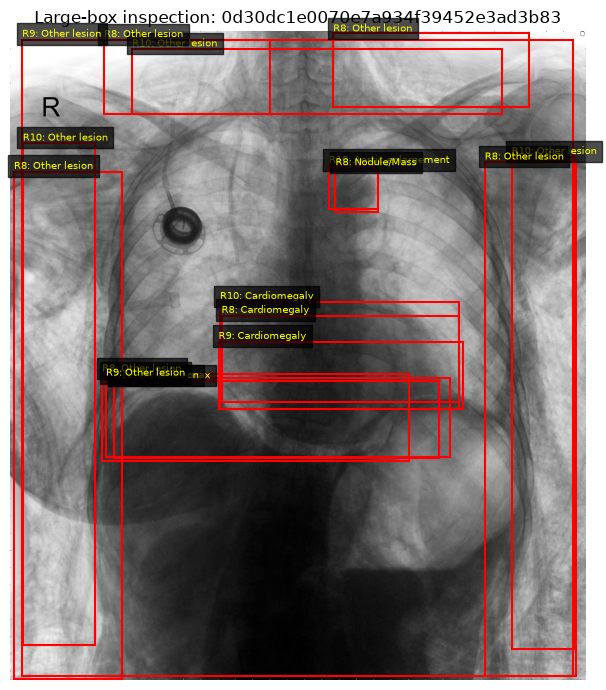

In [28]:

# Inspect the image with the largest bounding box.
image_id = "0d30dc1e0070e7a934f39452e3ad3b83"

row = manifest.loc[manifest["image_id"] == image_id].iloc[0]
ds = pydicom.dcmread(str(ROOT / row["dicom_path"]))
image = ds.pixel_array.astype(np.float32)

# Normalize for visualization.
lo, hi = np.percentile(image, [1, 99])
image = np.clip(image, lo, hi)
image = (image - lo) / max(hi - lo, 1e-8)

boxes = annotations[
    annotations["image_id"].astype(str) == image_id
].dropna(subset=["x_min", "y_min", "x_max", "y_max"])

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(image, cmap="gray")

for _, b in boxes.iterrows():
    x1, y1 = float(b["x_min"]), float(b["y_min"])
    x2, y2 = float(b["x_max"]), float(b["y_max"])

    ax.add_patch(plt.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="red", linewidth=1.5
    ))
    ax.text(
        x1, max(0, y1 - 10),
        f'{b["rad_id"]}: {b["class_name"]}',
        color="yellow", fontsize=7,
        bbox=dict(facecolor="black", alpha=0.7)
    )

ax.set_title(f"Large-box inspection: {image_id}")
ax.axis("off")
plt.tight_layout()
plt.show()
